In [1]:

from pathlib import Path
from collections import Counter
import re
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from IPython.display import display

from skimage.feature import hog
from skimage.morphology import skeletonize
from skimage.exposure import rescale_intensity

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    pairwise_distances
)
from sklearn.ensemble import RandomForestClassifier

SEED = 42
QUICK_RUN = False

# Chỉ dùng khi QUICK_RUN=True
QUICK_SOURCE_GROUPS = 20
QUICK_TEST_PER_CLASS = 100

# Cấu hình HOG D
IMG_SIZE = 128
HOG_PARAMS = {
    "orientations": 9,
    "pixels_per_cell": (16, 16),
    "cells_per_block": (2, 2),
    "block_norm": "L2-Hys",
    "feature_vector": True
}

# Cấu hình Random Forest
RF_PARAMS = {
    "n_estimators": 150,
    "max_depth": None,
    "min_samples_leaf": 2,
    "max_features": "sqrt",
    "random_state": SEED,
    "n_jobs": -1
}

# ReliefF
RELIEF_SAMPLES_PER_CLASS = 25
RELIEF_K = 5
RELIEF_RATIO = 0.50

CLASS_NAMES = [
    "AC Source",
    "Ammeter",
    "AND Gate",
    "Capacitor",
    "DC Source",
    "Ground",
    "Inductor",
    "NAND Gate",
    "NOR Gate",
    "NOT Gate",
    "NPN Transistor",
    "OR Gate",
    "PN Junction Diode",
    "PNP Transistor",
    "Power Supply",
    "Resistor",
    "Switch",
    "Transformer",
    "Voltmeter",
    "Zener Diode"
]

CLASSES = [f"{i:02d}" for i in range(1, 21)]
LABEL_MAP = dict(zip(CLASSES, CLASS_NAMES))

np.random.seed(SEED)

# Tự tìm thư mục gốc
candidates = [
    p for p in Path("/kaggle/input").rglob(
        "circuit-component-analysis"
    )
    if p.is_dir()
]

if not candidates:
    raise FileNotFoundError(
        "Not found circuit-component-analysis"
    )

BASE_DIR = candidates[0]

ORIGINAL_DIR = (
    BASE_DIR / "CktComDb-v1.o" / "CktComDb-v1.o"
)
AUGMENTED_DIR = (
    BASE_DIR / "CktComDb-v1.a" / "CktComDb-v1.a"
)
MIXED_DIR = (
    BASE_DIR / "CktComDb-v1.oa" / "CktComDb-v1.oa"
)

for folder in [ORIGINAL_DIR, AUGMENTED_DIR, MIXED_DIR]:
    assert folder.is_dir(), f"Missing: {folder}"

print("Dataset:", BASE_DIR)
print("Number of classes:", len(CLASSES))
print("Quick run:", QUICK_RUN)

display(pd.DataFrame({
    "ID": CLASSES,
    "Class Name": CLASS_NAMES
}))


Dataset: /kaggle/input/datasets/ayush02102001/circuit-component-analysis
Number of classes: 20
Quick run: False


,ID,Class Name
0,01,AC Source
1,02,Ammeter
2,03,AND Gate
3,04,Capacitor
4,05,DC Source
5,06,Ground
6,07,Inductor
7,08,NAND Gate
8,09,NOR Gate
9,10,NOT Gate


In [2]:

def get_images(root, split):
    paths = []

    for cls in CLASSES:
        folder = root / split / cls

        if not folder.is_dir():
            raise FileNotFoundError(folder)

        files = sorted(folder.glob("*.bmp"))

        if len(files) == 0:
            raise ValueError(f"No images in {folder}")

        paths.extend(files)

    return paths


originals = get_images(ORIGINAL_DIR, "Train")
augmentations = get_images(AUGMENTED_DIR, "Train")
all_test_paths = get_images(MIXED_DIR, "Test")

dataset_stats = pd.DataFrame([
    {
        "ID": cls,
        "Class": LABEL_MAP[cls],
        "Original Train": sum(
            p.parent.name == cls for p in originals
        ),
        "Augmented Train": sum(
            p.parent.name == cls for p in augmentations
        ),
        "Mixed Test": sum(
            p.parent.name == cls for p in all_test_paths
        )
    }
    for cls in CLASSES
])

display(dataset_stats)

print("Original Train:", len(originals))
print("Augmented Train:", len(augmentations))
print("Mixed Test:", len(all_test_paths))

print("\nFilename examples:")
print("Original:", originals[0].name)
print("Augmented:", augmentations[0].name)
print("Test:", all_test_paths[0].name)


,ID,Class,Original Train,Augmented Train,Mixed Test
0,01,AC Source,50,450,1000
1,02,Ammeter,50,450,1000
2,03,AND Gate,50,450,1000
3,04,Capacitor,50,450,1000
4,05,DC Source,50,450,1000
5,06,Ground,50,450,1000
6,07,Inductor,50,450,1000
7,08,NAND Gate,50,450,1000
8,09,NOR Gate,50,450,1000
9,10,NOT Gate,50,450,1000


Original Train: 1000
Augmented Train: 9000
Mixed Test: 20000

Filename examples:
Original: original_01.bmp
Augmented: augmented_01_01.bmp
Test: mixed_000.bmp


In [3]:

def original_key(path):
    m = re.fullmatch(
        r"original_(\d+)", path.stem, re.I
    )
    if m is None:
        raise ValueError(path.name)

    return path.parent.name, int(m.group(1))


def augmented_key(path):
    m = re.fullmatch(
        r"augmented_(\d+)_(\d+)", path.stem, re.I
    )
    if m is None:
        raise ValueError(path.name)

    # Số cuối là ID ảnh nguồn
    return path.parent.name, int(m.group(2))


all_original_keys = [original_key(p) for p in originals]
all_augmented_keys = [augmented_key(p) for p in augmentations]

assert len(all_original_keys) == len(set(all_original_keys))
assert set(all_augmented_keys) <= set(all_original_keys)

# Chọn nhóm ảnh nguồn
rng = np.random.default_rng(SEED)
selected_originals = []

for cls in CLASSES:
    files = sorted(
        p for p in originals if p.parent.name == cls
    )

    if QUICK_RUN:
        n = min(QUICK_SOURCE_GROUPS, len(files))
        idx = rng.choice(len(files), size=n, replace=False)
        files = [files[i] for i in sorted(idx)]

    selected_originals.extend(files)


# Chia theo ảnh gốc, stratified
train_orig, val_orig = train_test_split(
    selected_originals,
    test_size=0.20,
    stratify=[p.parent.name for p in selected_originals],
    random_state=SEED
)

train_ids = {original_key(p) for p in train_orig}
val_ids = {original_key(p) for p in val_orig}

assert train_ids.isdisjoint(val_ids)

# Ghép augmentation theo ID nguồn
train_aug = [
    p for p in augmentations
    if augmented_key(p) in train_ids
]

val_aug = [
    p for p in augmentations
    if augmented_key(p) in val_ids
]

train_paths = sorted(train_orig + train_aug)
val_paths = sorted(val_orig + val_aug)

# Giữ nguyên .oa/Test
test_paths = []

for cls in CLASSES:
    files = sorted(
        p for p in all_test_paths
        if p.parent.name == cls
    )

    if QUICK_RUN:
        n = min(QUICK_TEST_PER_CLASS, len(files))
        idx = rng.choice(len(files), size=n, replace=False)
        files = [files[i] for i in sorted(idx)]

    test_paths.extend(files)


y_train = np.array([
    p.parent.name for p in train_paths
])
y_val = np.array([
    p.parent.name for p in val_paths
])
y_test = np.array([
    p.parent.name for p in test_paths
])

# Kiểm tra không có nhóm nguồn bị trộn
assert train_ids.isdisjoint(val_ids)

assert all(
    augmented_key(p) in train_ids for p in train_aug
)
assert all(
    augmented_key(p) in val_ids for p in val_aug
)

assert len(train_paths) + len(val_paths) == (
    len(train_orig) + len(val_orig)
    + len(train_aug) + len(val_aug)
)

split_stats = pd.DataFrame([
    {
        "Class": LABEL_MAP[c],
        "Train": np.sum(y_train == c),
        "Validation": np.sum(y_val == c),
        "Test": np.sum(y_test == c)
    }
    for c in CLASSES
])

display(split_stats)

print("Train:", len(train_paths))
print("Validation:", len(val_paths))
print("Test:", len(test_paths))
print("Source groups disjoint: PASS")


,Class,Train,Validation,Test
0,AC Source,400,100,1000
1,Ammeter,400,100,1000
2,AND Gate,400,100,1000
3,Capacitor,400,100,1000
4,DC Source,400,100,1000
5,Ground,400,100,1000
6,Inductor,400,100,1000
7,NAND Gate,400,100,1000
8,NOR Gate,400,100,1000
9,NOT Gate,400,100,1000


Train: 8000
Validation: 2000
Test: 20000
Source groups disjoint: PASS


In [4]:

def preprocess(path):
    with Image.open(path) as im:
        img = im.convert("L")

        # Giữ nguyên tỷ lệ hình
        img = ImageOps.contain(
            img,
            (IMG_SIZE, IMG_SIZE),
            method=Image.Resampling.LANCZOS
        )

        # Padding trắng, căn giữa
        canvas = Image.new(
            "L", (IMG_SIZE, IMG_SIZE), 255
        )

        x = (IMG_SIZE - img.width) // 2
        y = (IMG_SIZE - img.height) // 2
        canvas.paste(img, (x, y))

    # Normalize [0,1]
    return np.asarray(
        canvas, dtype=np.float32
    ) / 255.0


def extract_hog(path):
    img = preprocess(path)

    return hog(
        img, **HOG_PARAMS
    ).astype(np.float32)


def extract_hog_dataset(paths):
    features = []

    for i, path in enumerate(paths):
        features.append(extract_hog(path))

        if (i + 1) % 2000 == 0:
            print(f"HOG: {i+1}/{len(paths)}")

    return np.stack(features)


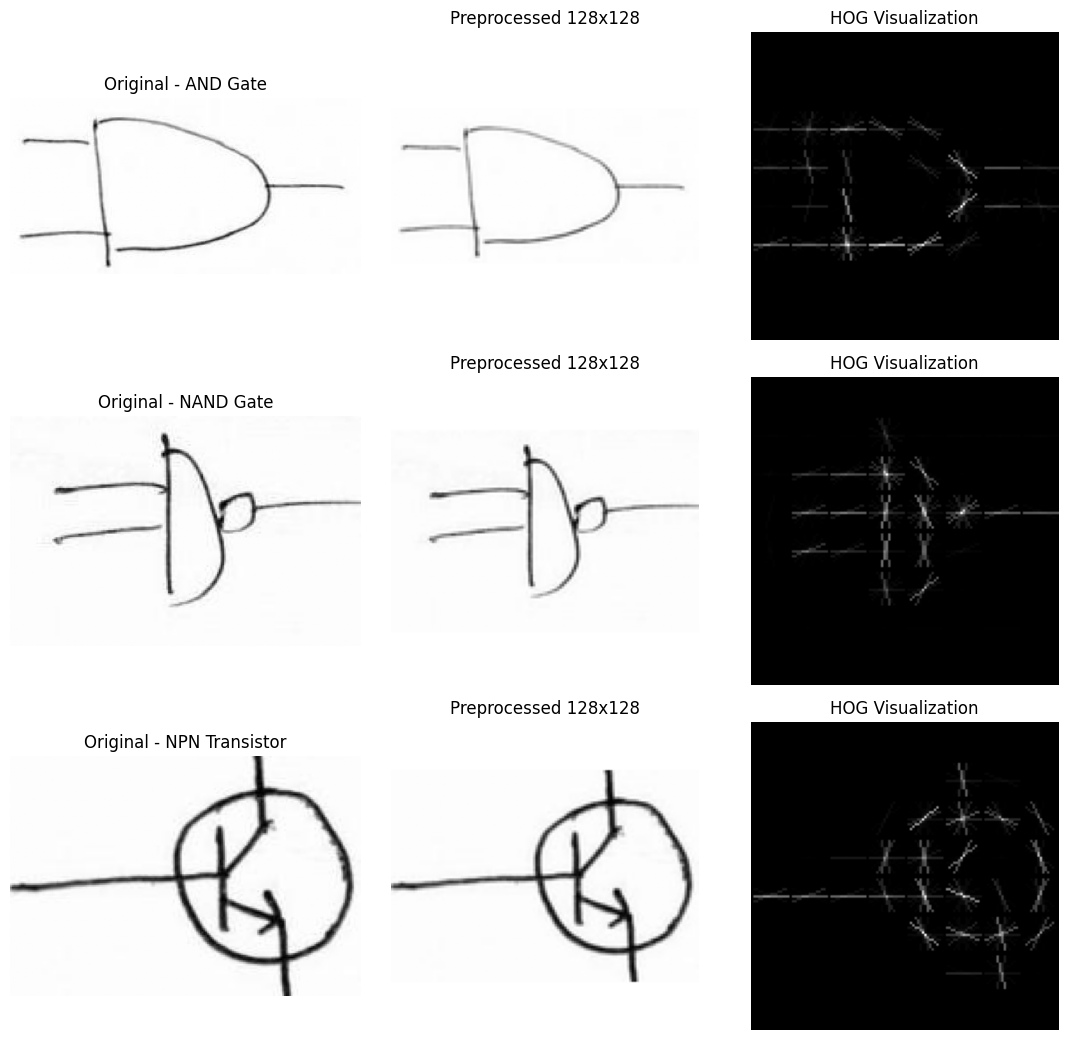

In [5]:

# Chọn ba ảnh gốc thuộc ba lớp khác nhau
sample_paths = []

for cls in ["03", "08", "11"]:
    matches = [
        p for p in train_orig
        if p.parent.name == cls
    ]
    if matches:
        sample_paths.append(matches[0])

fig, axes = plt.subplots(
    len(sample_paths), 3,
    figsize=(11, 3.5 * len(sample_paths)),
    squeeze=False
)

for i, path in enumerate(sample_paths):
    with Image.open(path) as im:
        original = np.asarray(im.convert("L"))

    processed = preprocess(path)

    _, hog_vis = hog(
        processed,
        **HOG_PARAMS,
        visualize=True
    )

    hog_vis = rescale_intensity(
        hog_vis, in_range="image"
    )

    axes[i, 0].imshow(original, cmap="gray")
    axes[i, 0].set_title(
        f"Original - {LABEL_MAP[path.parent.name]}"
    )

    axes[i, 1].imshow(
        processed, cmap="gray", vmin=0, vmax=1
    )
    axes[i, 1].set_title("Preprocessed 128x128")

    axes[i, 2].imshow(hog_vis, cmap="gray")
    axes[i, 2].set_title("HOG Visualization")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [6]:

start = time.perf_counter()

X_train_hog = extract_hog_dataset(train_paths)
X_val_hog = extract_hog_dataset(val_paths)

print("\n===== HOG =====")
print("Train:", X_train_hog.shape)
print("Validation:", X_val_hog.shape)
print("Extraction time:",
      round(time.perf_counter() - start, 2), "s")

assert X_train_hog.shape[1] == 1764
assert X_val_hog.shape[1] == 1764


HOG: 2000/8000
HOG: 4000/8000
HOG: 6000/8000
HOG: 8000/8000
HOG: 2000/2000

===== HOG =====
Train: (8000, 1764)
Validation: (2000, 1764)
Extraction time: 625.31 s


In [7]:

SHAPE_NAMES = (
    ["CD_" + x for x in [
        "max", "min", "mean", "std", "q25", "q50", "q75"
    ]]
    + ["TA_" + x for x in [
        "max", "min", "mean", "std", "q25", "q50", "q75"
    ]]
    + [f"CCH_{i}" for i in range(8)]
)


def stats7(values):
    values = np.asarray(values, dtype=np.float32)

    if values.size == 0:
        return np.zeros(7, dtype=np.float32)

    return np.array([
        np.max(values),
        np.min(values),
        np.mean(values),
        np.std(values),
        *np.percentile(values, [25, 50, 75])
    ], dtype=np.float32)


def get_binary_skeleton(path):
    img = np.clip(
        preprocess(path) * 255, 0, 255
    ).astype(np.uint8)

    # Nét đen -> foreground trắng (255)
    _, binary = cv2.threshold(
        img, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    skel = skeletonize(binary > 0)
    return binary, skel


def extract_shape(path):
    binary, skel = get_binary_skeleton(path)

    # ---- 1. Centroid Distance ----
    yy, xx = np.nonzero(skel)

    if len(xx) == 0:
        return np.zeros(22, dtype=np.float32)

    points = np.column_stack([xx, yy]).astype(
        np.float32
    )

    centroid = points.mean(axis=0)

    distances = np.linalg.norm(
        points - centroid, axis=1
    )

    # Chuẩn hóa theo kích thước ảnh
    distances /= (np.sqrt(2) * IMG_SIZE)

    cd_features = stats7(distances)

    # ---- 2. Tangent Angle + 3. CCH ----
    skel_img = (
        skel.astype(np.uint8) * 255
    )

    contours, _ = cv2.findContours(
        skel_img,
        cv2.RETR_LIST,
        cv2.CHAIN_APPROX_NONE
    )

    angles = []
    chain_counts = np.zeros(8, dtype=np.float64)

    direction_map = {
        (1, 0): 0,
        (1, -1): 1,
        (0, -1): 2,
        (-1, -1): 3,
        (-1, 0): 4,
        (-1, 1): 5,
        (0, 1): 6,
        (1, 1): 7
    }

    for contour in contours:
        pts = contour.reshape(-1, 2)

        if len(pts) < 2:
            continue

        # Không nối giả tạo điểm cuối về điểm đầu
        steps = np.diff(
            pts.astype(np.int32), axis=0
        )

        dx = steps[:, 0]
        dy = steps[:, 1]

        # Chỉ lấy các bước 8-neighbor hợp lệ
        valid = (
            ((dx != 0) | (dy != 0))
            & (np.abs(dx) <= 1)
            & (np.abs(dy) <= 1)
        )

        dx = dx[valid]
        dy = dy[valid]

        if len(dx) == 0:
            continue

        theta = np.arctan2(dy, dx)
        angles.extend(theta.tolist())

        for (sx, sy), code in direction_map.items():
            chain_counts[code] += np.sum(
                (dx == sx) & (dy == sy)
            )

    ta_features = stats7(angles)

    if chain_counts.sum() > 0:
        chain_counts /= chain_counts.sum()

    shape_vector = np.concatenate([
        cd_features,
        ta_features,
        chain_counts.astype(np.float32)
    ])

    assert len(shape_vector) == 22
    return shape_vector.astype(np.float32)


def extract_shape_dataset(paths):
    features = []

    for i, path in enumerate(paths):
        features.append(extract_shape(path))

        if (i + 1) % 2000 == 0:
            print(f"Shape: {i+1}/{len(paths)}")

    return np.stack(features)


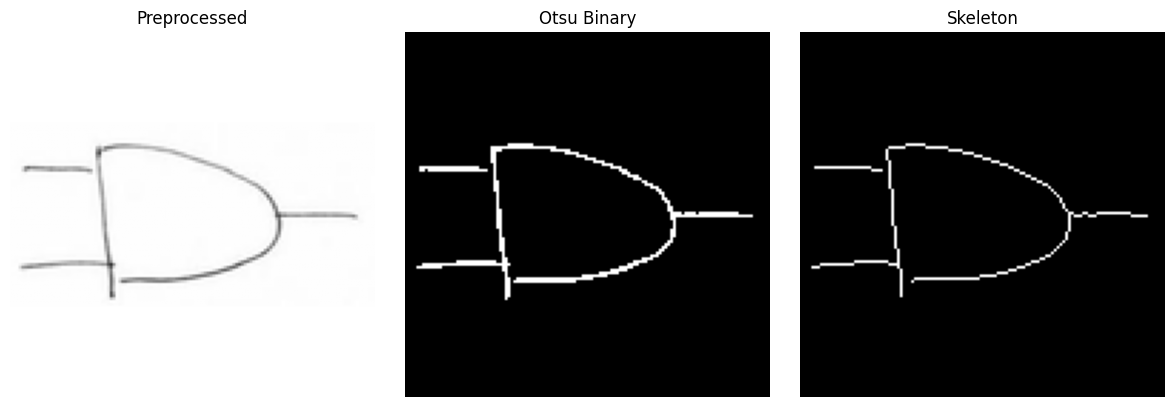

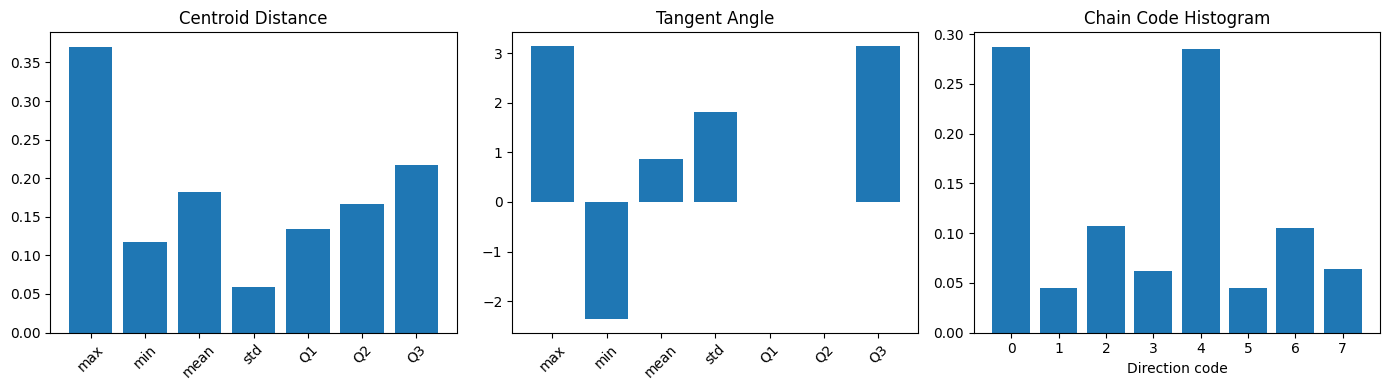

In [8]:

sample_path = sample_paths[0]

binary, skel = get_binary_skeleton(sample_path)
shape_vector = extract_shape(sample_path)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(
    preprocess(sample_path),
    cmap="gray", vmin=0, vmax=1
)
axes[0].set_title("Preprocessed")

axes[1].imshow(binary, cmap="gray")
axes[1].set_title("Otsu Binary")

axes[2].imshow(skel, cmap="gray")
axes[2].set_title("Skeleton")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].bar(range(7), shape_vector[:7])
axes[0].set_title("Centroid Distance")
axes[0].set_xticks(range(7))
axes[0].set_xticklabels(
    ["max", "min", "mean", "std", "Q1", "Q2", "Q3"],
    rotation=45
)

axes[1].bar(range(7), shape_vector[7:14])
axes[1].set_title("Tangent Angle")
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(
    ["max", "min", "mean", "std", "Q1", "Q2", "Q3"],
    rotation=45
)

axes[2].bar(range(8), shape_vector[14:22])
axes[2].set_title("Chain Code Histogram")
axes[2].set_xlabel("Direction code")

plt.tight_layout()
plt.show()


In [9]:

start = time.perf_counter()

X_train_shape = extract_shape_dataset(train_paths)
X_val_shape = extract_shape_dataset(val_paths)

print("\n===== SHAPE FEATURES =====")
print("Train:", X_train_shape.shape)
print("Validation:", X_val_shape.shape)
print("Extraction time:",
      round(time.perf_counter() - start, 2), "s")

assert X_train_shape.shape[1] == 22
assert X_val_shape.shape[1] == 22

assert np.isfinite(X_train_shape).all()
assert np.isfinite(X_val_shape).all()


Shape: 2000/8000
Shape: 4000/8000
Shape: 6000/8000
Shape: 8000/8000
Shape: 2000/2000

===== SHAPE FEATURES =====
Train: (8000, 22)
Validation: (2000, 22)
Extraction time: 33.09 s


In [10]:

def approximate_relieff(
    X, y,
    samples_per_class=25,
    k=5,
    seed=42
):
    rng = np.random.default_rng(seed)
    y = np.asarray(y)

    # Lấy mẫu cân bằng từ Train
    selected_rows = []

    for cls in np.unique(y):
        ids = np.flatnonzero(y == cls)
        n = min(samples_per_class, len(ids))

        chosen = rng.choice(
            ids, size=n, replace=False
        )
        selected_rows.extend(chosen)

    selected_rows = np.array(selected_rows)
    y_sub = y[selected_rows]

    # Chuẩn hóa chỉ trên mẫu thuộc Train
    scaler = MinMaxScaler()
    Z = scaler.fit_transform(
        X[selected_rows]
    ).astype(np.float32)

    # Ma trận khoảng cách
    D = pairwise_distances(
        Z, metric="euclidean", n_jobs=1
    )
    np.fill_diagonal(D, np.inf)

    classes = np.unique(y_sub)

    class_indices = {
        c: np.flatnonzero(y_sub == c)
        for c in classes
    }

    priors = {
        c: len(class_indices[c]) / len(y_sub)
        for c in classes
    }

    scores = np.zeros(
        Z.shape[1], dtype=np.float64
    )

    m = len(Z)

    for i in range(m):
        current_class = y_sub[i]

        # Nearest Hits: cùng lớp
        hit_ids = class_indices[current_class]
        hit_ids = hit_ids[hit_ids != i]

        n_hit = min(k, len(hit_ids))

        if n_hit == 0:
            continue

        nearest_hits = hit_ids[
            np.argsort(D[i, hit_ids])[:n_hit]
        ]

        hit_diff = np.abs(
            Z[nearest_hits] - Z[i]
        ).mean(axis=0)

        scores -= hit_diff / m

        # Nearest Misses: khác lớp
        for other_class in classes:
            if other_class == current_class:
                continue

            miss_ids = class_indices[other_class]
            n_miss = min(k, len(miss_ids))

            nearest_misses = miss_ids[
                np.argsort(D[i, miss_ids])[:n_miss]
            ]

            miss_diff = np.abs(
                Z[nearest_misses] - Z[i]
            ).mean(axis=0)

            weight = (
                priors[other_class]
                / (1.0 - priors[current_class])
            )

            scores += weight * miss_diff / m

    ranking = np.argsort(scores)[::-1]

    return ranking, scores


start = time.perf_counter()

relief_ranking, relief_scores = approximate_relieff(
    X_train_hog,
    y_train,
    samples_per_class=RELIEF_SAMPLES_PER_CLASS,
    k=RELIEF_K,
    seed=SEED
)

N_SELECTED = int(
    X_train_hog.shape[1] * RELIEF_RATIO
)

selected_hog_idx = relief_ranking[:N_SELECTED]

print("Original HOG:", X_train_hog.shape[1])
print("Selected HOG:", len(selected_hog_idx))
print("ReliefF time:",
      round(time.perf_counter() - start, 2), "s")


Original HOG: 1764
Selected HOG: 882
ReliefF time: 0.51 s


===== FEATURE DIMENSIONS =====
F1 HOG Train: (8000, 1764) Validation: (2000, 1764)
F2 HOG + Shape Train: (8000, 1786) Validation: (2000, 1786)
F3 ReliefF-HOG + Shape Train: (8000, 904) Validation: (2000, 904)


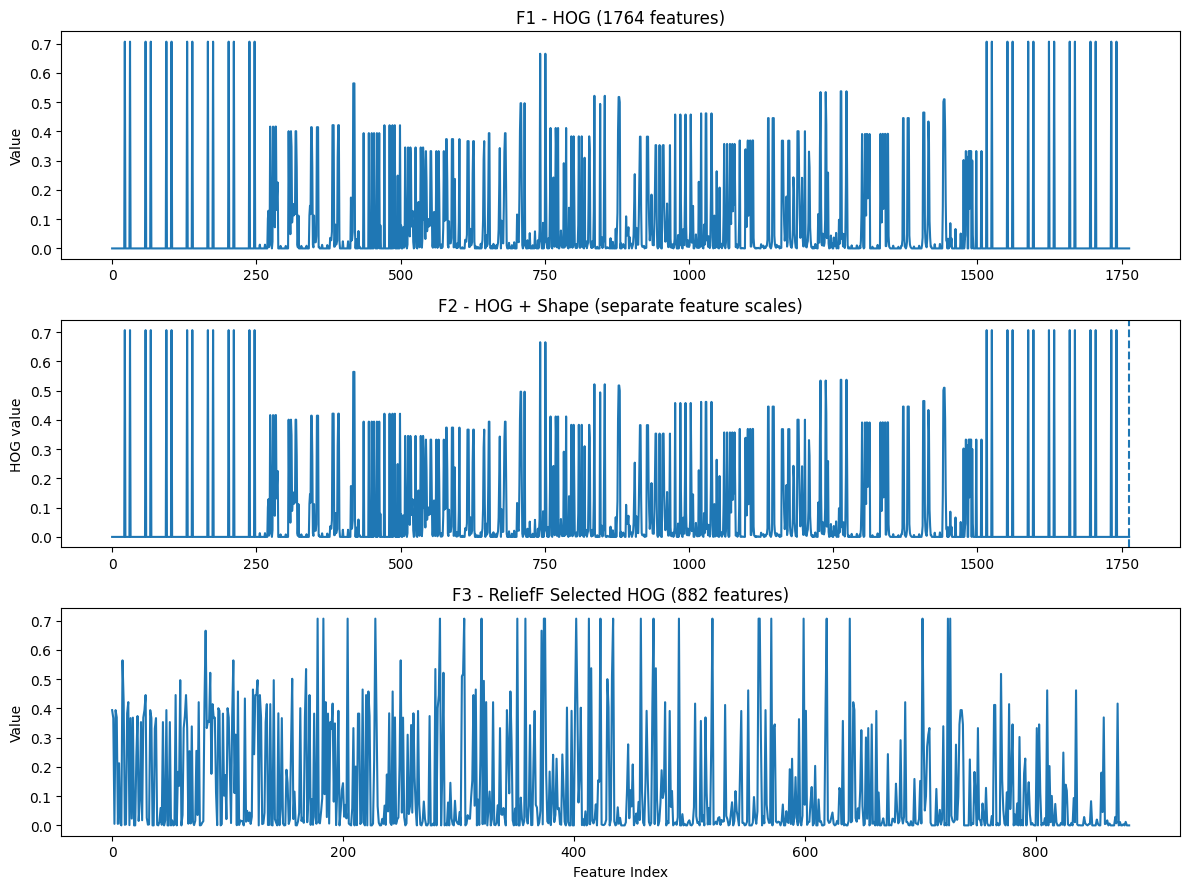

In [11]:

# F1: HOG
F1_train = X_train_hog
F1_val = X_val_hog

# F2: HOG + Shape
F2_train = np.hstack([
    X_train_hog, X_train_shape
])
F2_val = np.hstack([
    X_val_hog, X_val_shape
])

# F3: Selected HOG + Shape
F3_train = np.hstack([
    X_train_hog[:, selected_hog_idx],
    X_train_shape
])
F3_val = np.hstack([
    X_val_hog[:, selected_hog_idx],
    X_val_shape
])

feature_sets = {
    "F1": (F1_train, F1_val),
    "F2": (F2_train, F2_val),
    "F3": (F3_train, F3_val)
}

feature_descriptions = {
    "F1": "HOG",
    "F2": "HOG + Shape",
    "F3": "ReliefF-HOG + Shape"
}

print("===== FEATURE DIMENSIONS =====")
for name, (Xt, Xv) in feature_sets.items():
    print(
        name,
        feature_descriptions[name],
        "Train:", Xt.shape,
        "Validation:", Xv.shape
    )

assert F1_train.shape[1] == 1764
assert F2_train.shape[1] == 1786
assert F3_train.shape[1] == 904


# ===== VISUALIZE FEATURE VECTORS =====
sample_path = sample_paths[0]

hog_vec = extract_hog(sample_path)
shape_vec = extract_shape(sample_path)

fig, axes = plt.subplots(3, 1, figsize=(12, 9))

axes[0].plot(hog_vec)
axes[0].set_title(
    f"F1 - HOG ({len(hog_vec)} features)"
)
axes[0].set_ylabel("Value")

axes[1].plot(hog_vec)
axes[1].axvline(
    len(hog_vec) - 1,
    linestyle="--",
    label="End of HOG"
)
axes[1].set_title(
    "F2 - HOG + Shape (separate feature scales)"
)
axes[1].set_ylabel("HOG value")

axes[2].plot(hog_vec[selected_hog_idx])
axes[2].set_title(
    f"F3 - ReliefF Selected HOG ({N_SELECTED} features)"
)
axes[2].set_xlabel("Feature Index")
axes[2].set_ylabel("Value")

plt.tight_layout()
plt.show()

# Riêng 22 Shape Features đã có ở Cell 8


In [12]:
import joblib

joblib.dump({
    "X_train_hog": X_train_hog,
    "X_val_hog": X_val_hog,
    "X_train_shape": X_train_shape,
    "X_val_shape": X_val_shape,
    "selected_hog_idx": selected_hog_idx,
    "y_train": y_train,
    "y_val": y_val
}, "/kaggle/working/feature_cache.joblib")

print("Feature cache saved!")

Feature cache saved!


In [13]:
def build_model():
    return RandomForestClassifier(**RF_PARAMS)


In [14]:
validation_results = []

for feature_name, (Xt, Xv) in feature_sets.items():
    print("\nTraining: RF +", feature_name)
    model = build_model()

    start_train = time.perf_counter()
    model.fit(Xt, y_train)
    train_time = time.perf_counter() - start_train

    start_pred = time.perf_counter()
    pred = model.predict(Xv)
    predict_time = time.perf_counter() - start_pred

    result = {
        "Classifier": "RF",
        "Features": feature_name,
        "Dimensions": Xt.shape[1],
        "Val Accuracy": accuracy_score(y_val, pred),
        "Val Precision": precision_score(y_val, pred, average="macro", zero_division=0),
        "Val Recall": recall_score(y_val, pred, average="macro", zero_division=0),
        "Val Macro F1": f1_score(y_val, pred, average="macro", zero_division=0),
        "Train Time (s)": train_time,
        "Predict Time (s)": predict_time,
    }
    validation_results.append(result)
    print(f"Accuracy: {result['Val Accuracy']:.4f}")
    print(f"Macro F1: {result['Val Macro F1']:.4f}")
    print(f"Training: {train_time:.2f}s")

results_df = pd.DataFrame(validation_results)
print("\n===== VALIDATION RESULTS =====")
display(results_df.round(4))



Training: RF + F1
Accuracy: 0.8355
Macro F1: 0.8326
Training: 13.06s

Training: RF + F2
Accuracy: 0.8390
Macro F1: 0.8358
Training: 13.23s

Training: RF + F3
Accuracy: 0.8345
Macro F1: 0.8316
Training: 12.99s

===== VALIDATION RESULTS =====


,Classifier,Features,Dimensions,Val Accuracy,Val Precision,Val Recall,Val Macro F1,Train Time (s),Predict Time (s)
0,RF,F1,1764,0.8355,0.8329,0.8355,0.8326,13.0561,0.0683
1,RF,F2,1786,0.8390,0.8374,0.8390,0.8358,13.2330,0.0666
2,RF,F3,904,0.8345,0.8334,0.8345,0.8316,12.9931,0.0661


,Val Accuracy,Val Macro F1
Features,,
F1,0.8355,0.8326
F2,0.8390,0.8358
F3,0.8345,0.8316


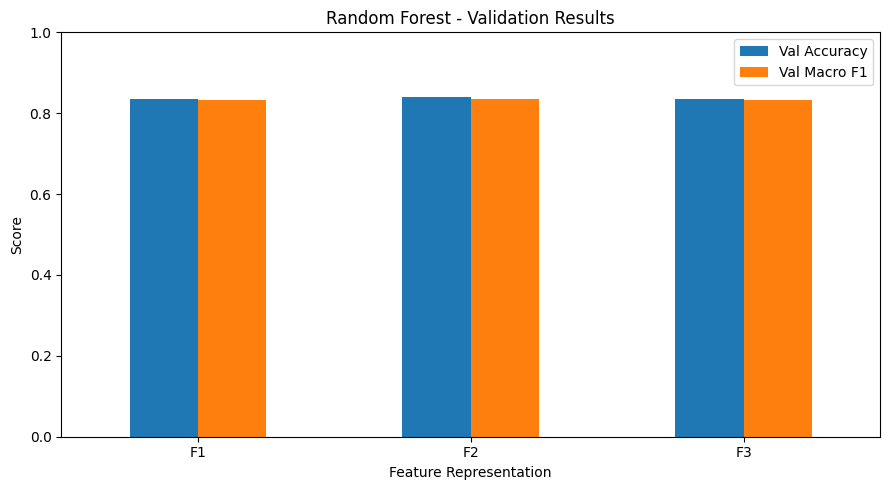

In [15]:
rf_validation = results_df.set_index("Features").reindex(feature_sets)
display(rf_validation[["Val Accuracy", "Val Macro F1"]].round(4))

axes = rf_validation[["Val Accuracy", "Val Macro F1"]].plot(
    kind="bar", figsize=(9, 5), rot=0
)
axes.set_title("Random Forest - Validation Results")
axes.set_xlabel("Feature Representation")
axes.set_ylabel("Score")
axes.set_ylim(0, 1)
plt.tight_layout()
plt.show()


In [16]:
best_row = results_df.sort_values(
    ["Val Macro F1", "Val Accuracy"], ascending=[False, False]
).iloc[0]
best_feature = best_row["Features"]
print(
    f"RF: {best_feature} | "
    f"Val Accuracy={best_row['Val Accuracy']:.4f} | "
    f"Val Macro F1={best_row['Val Macro F1']:.4f}"
)


RF: F2 | Val Accuracy=0.8390 | Val Macro F1=0.8358


In [17]:
# Trích xuất đặc trưng Test theo cấu hình thắng trên Validation.
X_test_hog = extract_hog_dataset(test_paths)

if best_feature in ("F2", "F3"):
    X_test_shape = extract_shape_dataset(test_paths)

if best_feature == "F1":
    X_test_selected = X_test_hog
elif best_feature == "F2":
    X_test_selected = np.hstack([X_test_hog, X_test_shape])
else:
    X_test_selected = np.hstack([
        X_test_hog[:, selected_hog_idx], X_test_shape
    ])

# Refit RF trên Train + Validation; chỉ đánh giá Test một lần.
Xt, Xv = feature_sets[best_feature]
X_final = np.vstack([Xt, Xv])
y_final = np.concatenate([y_train, y_val])
final_model = build_model()

print(f"\n===== RF + {best_feature} =====")
start = time.perf_counter()
final_model.fit(X_final, y_final)
train_time = time.perf_counter() - start

chunks = [
    final_model.predict(X_test_selected[i:i + 500])
    for i in range(0, len(X_test_selected), 500)
]
test_pred = np.concatenate(chunks)

test_accuracy = accuracy_score(y_test, test_pred)
test_macro_f1 = f1_score(y_test, test_pred, average="macro", zero_division=0)
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Macro F1: {test_macro_f1:.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test, test_pred, labels=CLASSES,
    target_names=CLASS_NAMES, zero_division=0
))

test_results = pd.DataFrame([{
    "Classifier": "RF", "Features": best_feature,
    "Test Accuracy": test_accuracy,
    "Test Macro F1": test_macro_f1,
    "Train Time (s)": train_time,
}])
print("\n===== FINAL TEST RESULTS =====")
display(test_results.round(4))


HOG: 2000/20000
HOG: 4000/20000
HOG: 6000/20000
HOG: 8000/20000
HOG: 10000/20000
HOG: 12000/20000
HOG: 14000/20000
HOG: 16000/20000
HOG: 18000/20000
Shape: 8000/20000
Shape: 10000/20000
Shape: 12000/20000
Shape: 14000/20000
Shape: 16000/20000
Shape: 18000/20000
Shape: 20000/20000

===== RF + F2 =====
Accuracy: 0.7070
Macro F1: 0.7060

Classification Report:
                   precision    recall  f1-score   support

        AC Source       0.52      0.65      0.58      1000
          Ammeter       0.59      0.67      0.63      1000
         AND Gate       0.50      0.59      0.54      1000
        Capacitor       0.76      0.73      0.74      1000
        DC Source       0.72      0.84      0.78      1000
           Ground       0.88      0.96      0.92      1000
         Inductor       0.80      0.85      0.82      1000
        NAND Gate       0.66      0.41      0.51      1000
         NOR Gate       0.61      0.75      0.67      1000
         NOT Gate       0.58      0.70      0.63 

,Classifier,Features,Test Accuracy,Test Macro F1,Train Time (s)
0,RF,F2,0.707,0.706,18.1787


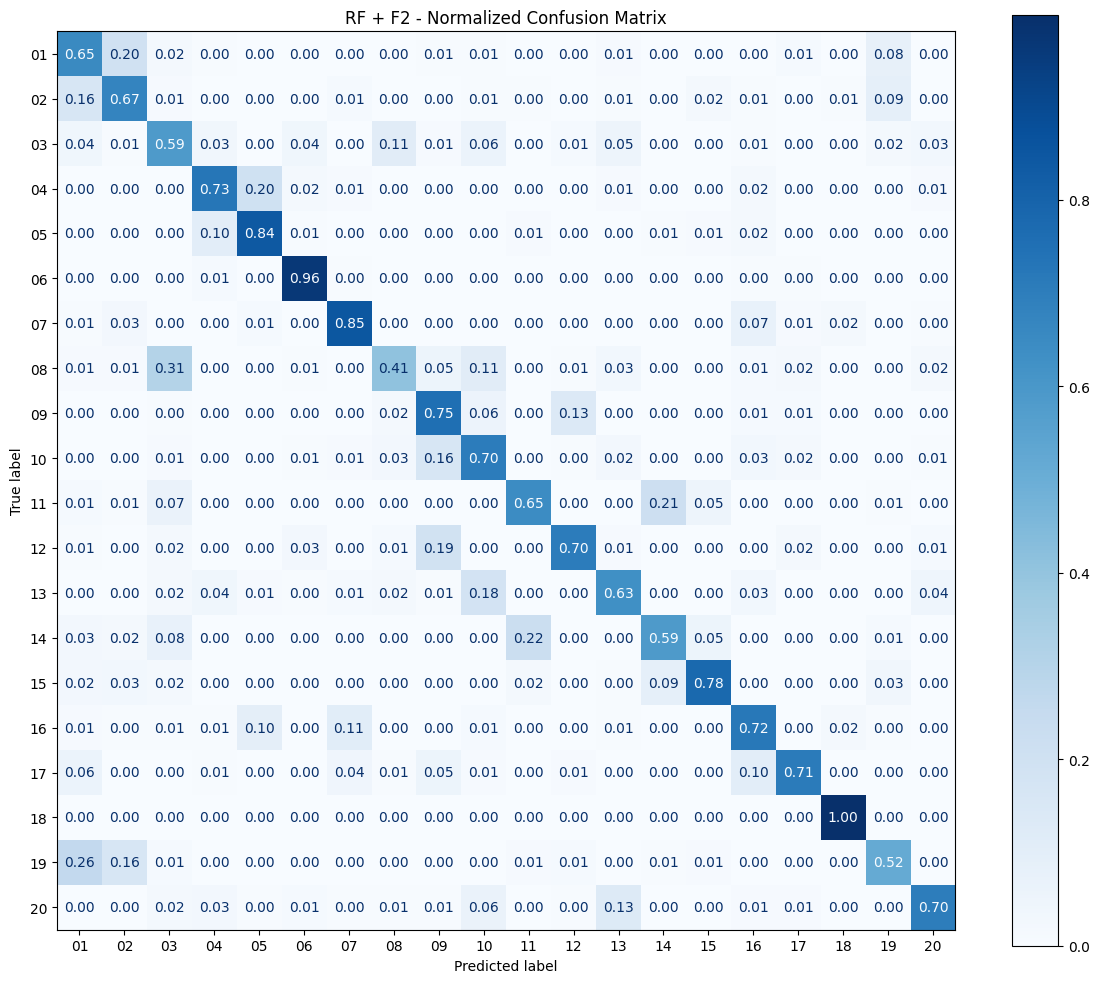


Top 10 confusions: RF


,True Class,Predicted Class,Count
89,NAND Gate,AND Gate,306
208,Voltmeter,AC Source,260
165,PNP Transistor,NPN Transistor,224
130,NPN Transistor,PNP Transistor,213
46,Capacitor,DC Source,201
0,AC Source,Ammeter,197
138,OR Gate,NOR Gate,189
152,PN Junction Diode,NOT Gate,182
120,NOT Gate,NOR Gate,162
209,Voltmeter,Ammeter,161


In [18]:
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, labels=CLASSES, display_labels=CLASSES,
    normalize="true", cmap="Blues", values_format=".2f", ax=ax
)
ax.set_title(f"RF + {best_feature} - Normalized Confusion Matrix")
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_test, test_pred, labels=CLASSES)
np.fill_diagonal(cm, 0)
mistakes = [
    {"True Class": CLASS_NAMES[i], "Predicted Class": CLASS_NAMES[j],
     "Count": int(cm[i, j])}
    for i in range(len(CLASSES)) for j in range(len(CLASSES))
    if cm[i, j] > 0
]
print("\nTop 10 confusions: RF")
display(pd.DataFrame(mistakes).sort_values("Count", ascending=False).head(10))


RF: 5860 wrong predictions / 20000 images


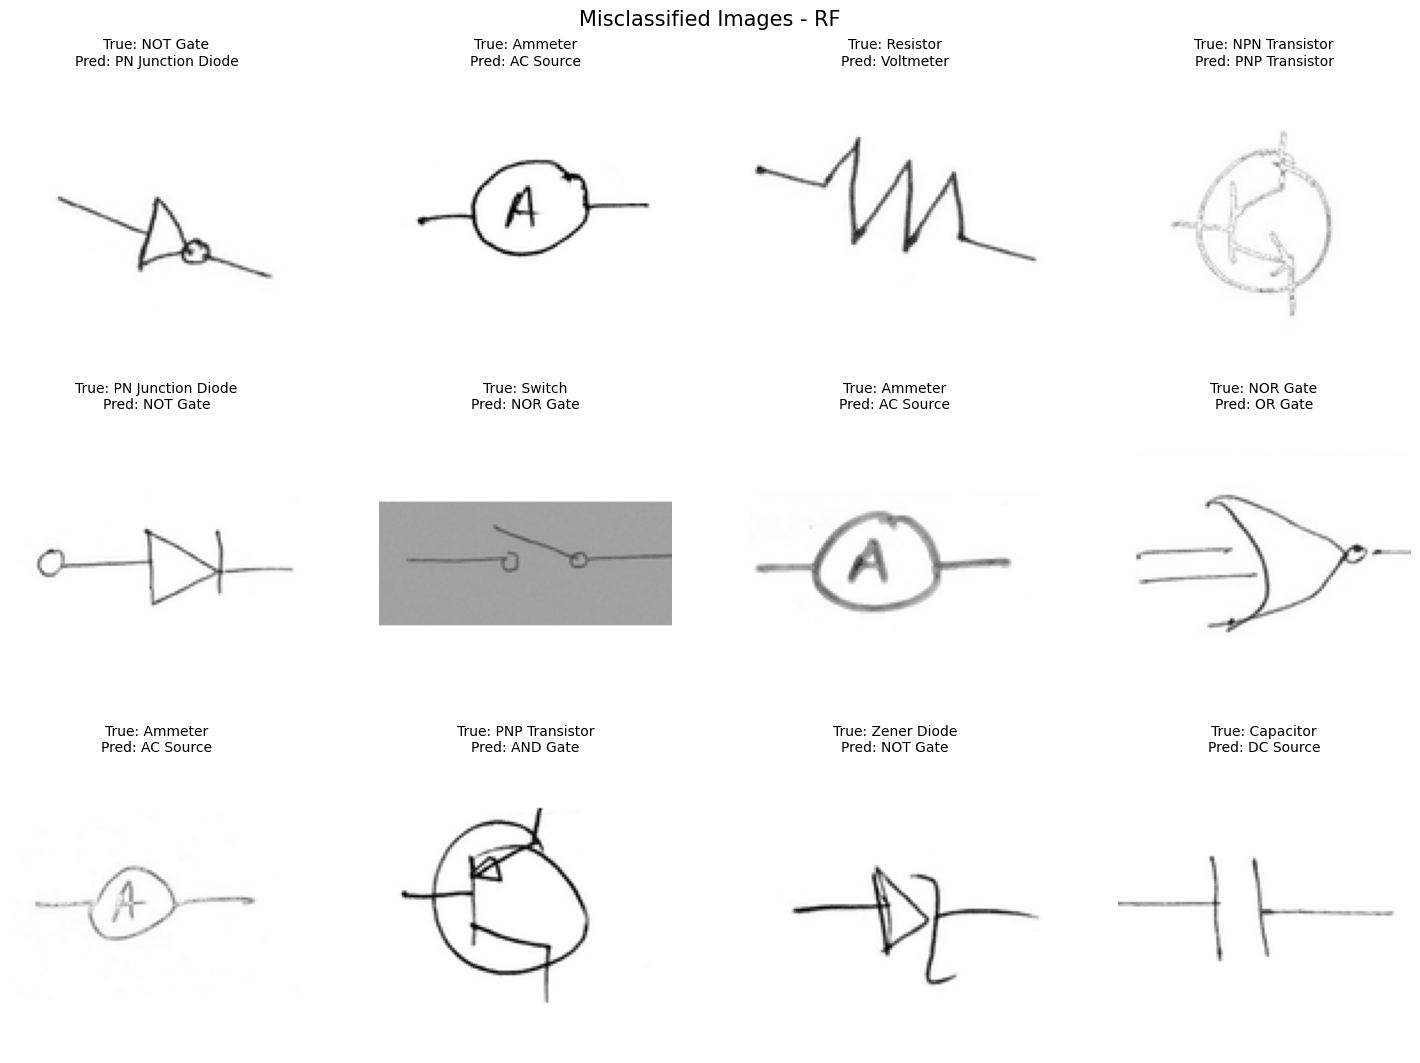

In [19]:
def show_misclassified_images(n_images=12):
    wrong_indices = np.flatnonzero(y_test != test_pred)
    print(f"RF: {len(wrong_indices)} wrong predictions / {len(y_test)} images")
    if len(wrong_indices) == 0:
        print("No misclassified images.")
        return

    rng = np.random.default_rng(SEED)
    selected = rng.choice(
        wrong_indices, size=min(n_images, len(wrong_indices)), replace=False
    )
    columns = 4
    rows = int(np.ceil(len(selected) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(15, rows * 3.6), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, idx in zip(axes.flat, selected):
        ax.imshow(preprocess(test_paths[idx]), cmap="gray", vmin=0, vmax=1)
        ax.set_title(
            f"True: {LABEL_MAP[y_test[idx]]}\nPred: {LABEL_MAP[test_pred[idx]]}",
            fontsize=10
        )
    fig.suptitle("Misclassified Images - RF", fontsize=15)
    plt.tight_layout()
    plt.show()

show_misclassified_images(n_images=12)


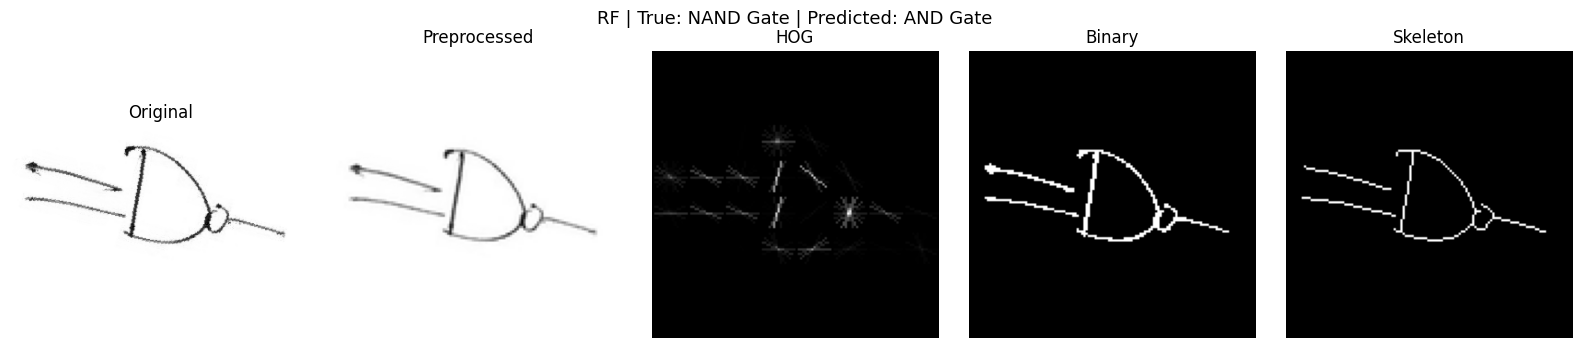

In [20]:
def show_error_diagnostics():
    cm = confusion_matrix(y_test, test_pred, labels=CLASSES)
    np.fill_diagonal(cm, 0)
    if cm.max() == 0:
        print("No errors found.")
        return

    true_i, pred_i = np.unravel_index(np.argmax(cm), cm.shape)
    true_id, pred_id = CLASSES[true_i], CLASSES[pred_i]
    idx = np.flatnonzero((y_test == true_id) & (test_pred == pred_id))[0]
    path = test_paths[idx]
    with Image.open(path) as im:
        original_image = np.asarray(im.convert("L"))
    processed = preprocess(path)
    binary, skel = get_binary_skeleton(path)
    _, hog_vis = hog(processed, **HOG_PARAMS, visualize=True)
    hog_vis = rescale_intensity(hog_vis, in_range="image")

    fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
    for ax, img, title in zip(
        axes, [original_image, processed, hog_vis, binary, skel],
        ["Original", "Preprocessed", "HOG", "Binary", "Skeleton"]
    ):
        ax.imshow(img, cmap="gray")
        ax.set_title(title)
        ax.axis("off")
    fig.suptitle(
        f"RF | True: {LABEL_MAP[true_id]} | Predicted: {LABEL_MAP[pred_id]}",
        fontsize=13
    )
    plt.tight_layout()
    plt.show()

show_error_diagnostics()


In [21]:
import joblib

SAVE_DIR = Path("/kaggle/working/saved_models")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(final_model, SAVE_DIR / "random_forest.joblib")

feature_config = {
    "img_size": IMG_SIZE,
    "hog_params": HOG_PARAMS,
    "best_feature": best_feature,
    "selected_hog_idx": selected_hog_idx,
    "classes": CLASSES,
    "class_names": CLASS_NAMES,
    "label_map": LABEL_MAP,
    "shape_names": SHAPE_NAMES,
    "rf_params": RF_PARAMS,
}
joblib.dump(feature_config, SAVE_DIR / "feature_config.joblib")

for path in [SAVE_DIR / "random_forest.joblib", SAVE_DIR / "feature_config.joblib"]:
    print(f"Saved: {path} ({path.stat().st_size / (1024 ** 2):.2f} MB)")


Saved: /kaggle/working/saved_models/random_forest.joblib (64.42 MB)
Saved: /kaggle/working/saved_models/feature_config.joblib (0.01 MB)


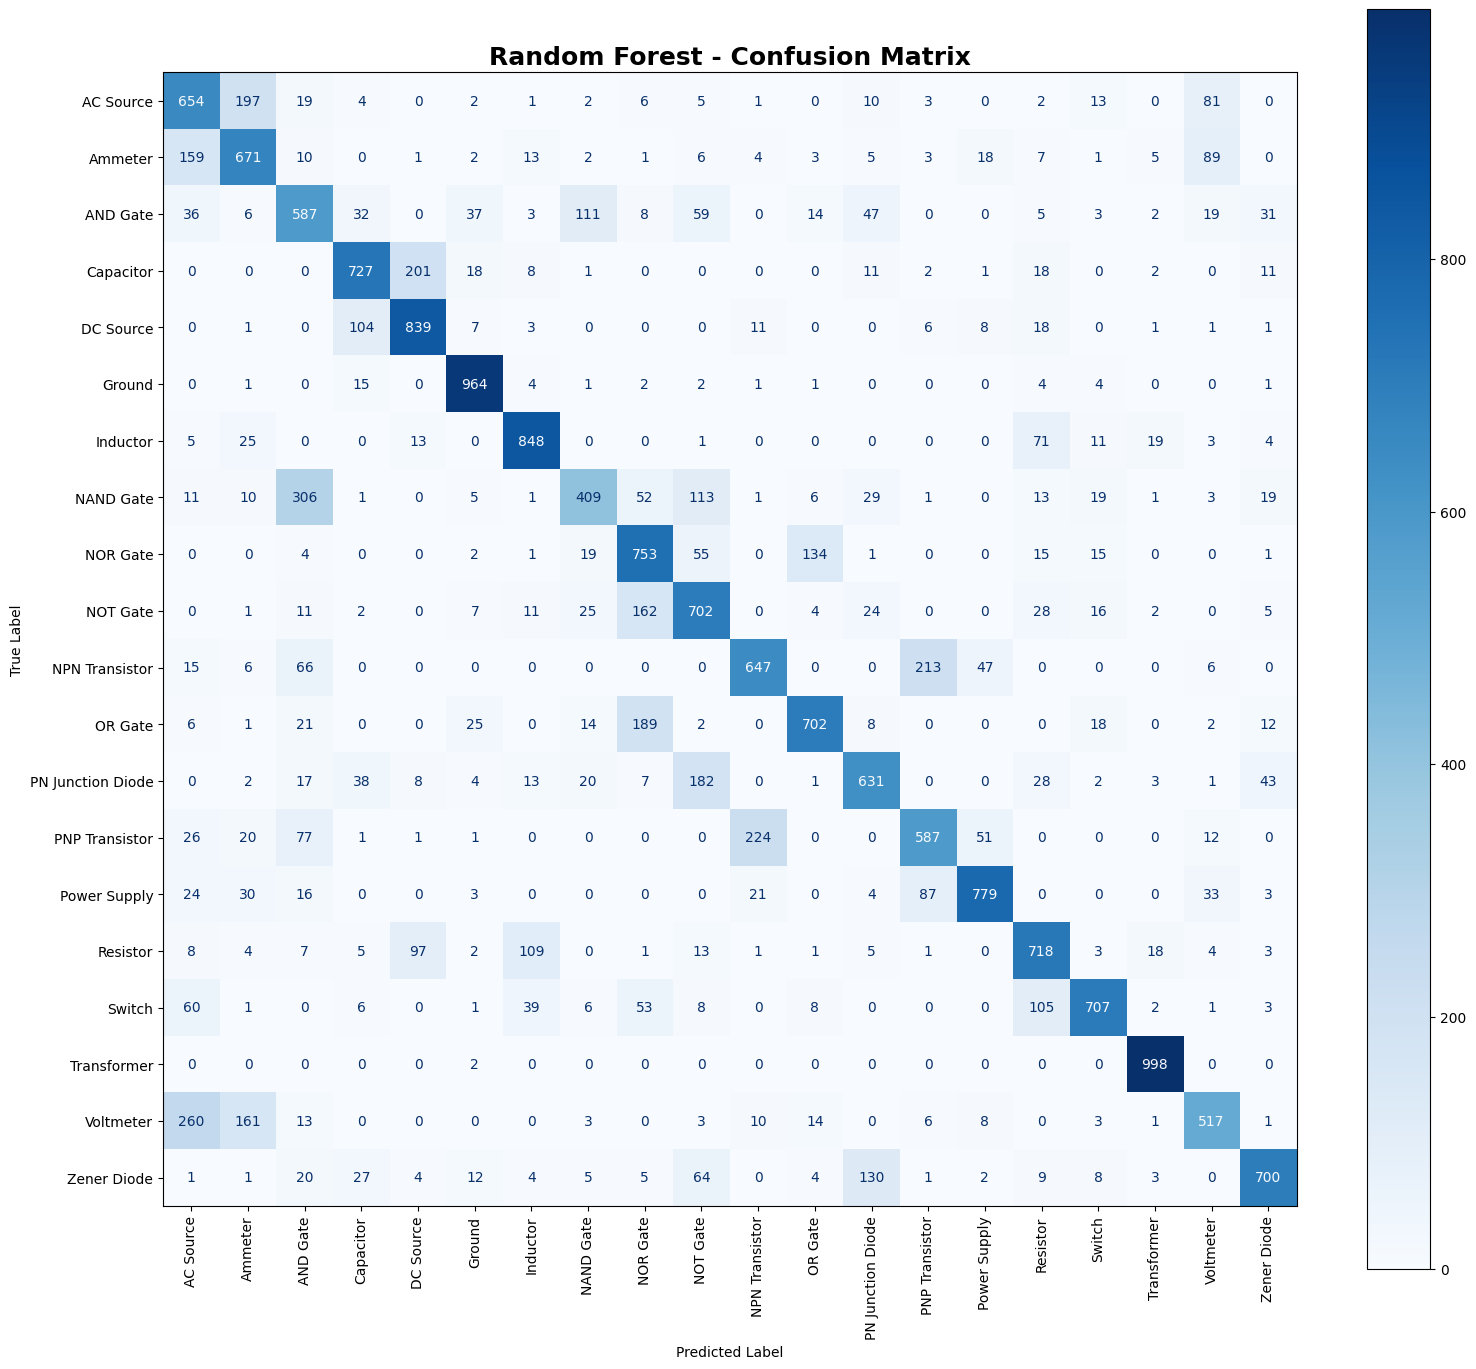

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(16, 14))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    labels=CLASSES,
    display_labels=CLASS_NAMES,
    normalize=None,
    values_format="d",
    cmap="Blues",
    xticks_rotation=90,
    ax=ax
)

ax.set_title(
    "Random Forest - Confusion Matrix",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()

In [23]:
from pathlib import Path

for name in [
    "final_predictions",
    "final_models",
    "X_train_hog",
    "X_train_shape",
    "X_test_hog",
    "X_test_shape",
    "y_test"
]:
    print(f"{name}: {name in globals()}")

print("\nSaved files:")
for p in Path("/kaggle/working").iterdir():
    print(p.name)

final_predictions: False
final_models: False
X_train_hog: True
X_train_shape: True
X_test_hog: True
X_test_shape: True
y_test: True

Saved files:
.virtual_documents
saved_models
feature_cache.joblib
